In [1]:
import tensorflow as tf

In [2]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


### MNIST in Keras

In [3]:
from tensorflow.keras.datasets import mnist

In [4]:
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

11490434/11490434 [==============================] - 1s 0us/step


In [5]:
from tensorflow import keras

De topologie van een model definieert een hypothese ruimte. We hebben machine learning beschreven als het zoeken naar nuttige representaties van bepaalde invoergegevens, binnen een vooraf gedefinieerde ruimte van mogelijkheden, met behulp van sturing via een feedbacksignaal. De keuze van de netwerktopologie beperkt de ruimte van mogelijkheden (hypothese ruimte) tot een specifieke reeks van tensoroperaties, die invoergegevens naar uitvoergegevens omvormten. Wat gezocht wordt binnen de hypotheseruimte is een goede set van waarden voor de gewichtstensors die betrokken zijn bij deze tensoroperaties.  

Om van gegevens te leren, moet je er aannames over maken. Deze aannames definiëren wat er geleerd kan worden. Als zodanig is de structuur van de hypothese ruimte - de architectuur van het model - uiterst belangrijk. Het legt de aannames die u maakt over uw probleem vast in de code, en vormt de voorkennis waarmee het model begint.  

Bijvoorbeeld, als je werkt aan een classificatieprobleem met 2 klassen en je gebruikt een model gemaakt van een enkele Dense laag zonder activatie (een pure affiene transformatie), dan neem je aan dat uw twee klassen lineair scheidbaar zijn.  

Het kiezen van de juiste netwerkarchitectuur is meer een kunst dan een wetenschap, en hoewel er enkele beste praktijken en principes zijn waarop je kunt vertrouwen, kan alleen de praktijk helpen een goede neurale-netwerkarchitect te worden.

In [6]:
from tensorflow.keras import layers
model = keras.Sequential([
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

Maak het model klaar om te trainen.  Hiervoor hebben we nodig:  

    Een optimizer.  Dit is het mechanisme waarmee het model zichzelf zal updaten gebaseerd op de training data die het ziet.  
    
    Een loss functie.  Hoe meet het model zijn performantie?  
    
    Parameters om te monitoren tijdens trainen en testen.  We kiezen hier accuracy (de fractie correct 
    geklasseerde afbeeldingen)


Het kiezen van de juiste loss function voor het juiste probleem is uiterst belangrijk: het netwerk zal elke shortcut nemen die het kan om de loss te minimaliseren en dingen doen die misschien niet gewenst zijn.  Gelukkig zijn er, als het gaat om gangbare problemen zoals classificatie en regressie, eenvoudige richtlijnen die u kunt volgen om de juiste loss function te kiezen. Zo gebruik je bijvoorbeeld binary crossentropy voor een classificatieprobleem met twee klassen, categorical crossentropy voor een classificatieprobleem met veel klassen, enzovoort. Alleen wanneer u werkt aan echt nieuwe onderzoeksproblemen, zult u uw eigen verliesfuncties moeten ontwikkelen.

In [7]:
# Compileer het model
model.compile(optimizer="rmsprop",
             loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])

In [8]:
# De MNIST data kunnen niet zomaar aan het model gegeven worden om te trainen:
train_images.shape

(60000, 28, 28)

In [9]:
# opvragen van het aantal dimensies van de tensor:
train_images.ndim

3

In [10]:
# opvragen van het datatype van de tensor:
train_images.dtype

dtype('uint8')

In [11]:
# train_images

In [12]:
# Dit zijn 60000 samples (afbeeldingen) van 28 op 28 pixels.  
# Het model kan niet overweg met 28 op 28 pixels, dus moeten we naar een "vlakke" structuur van 28*28 waarden.
# We schalen ook tussen nul en 1.  Dit kan eenvoudig door elke waarde te delen door 255

train_images = train_images.reshape((60000, 28*28))
train_images = train_images.astype("float32") / 255

test_images = test_images.reshape((10000, 28*28))
test_images = test_images.astype("float32") / 255

In [13]:
# opvragen van het aantal dimensies (de 'rank') van de tensor:
train_images.ndim

2

In [14]:
# opvragen van het datatype van de tensor:
train_images.dtype

dtype('float32')

**De fit() methode implementeert de trainingslus zelf. Dit zijn de belangrijkste argumenten:**

De gegevens (inputs en doelen) om mee te trainen. Deze worden meestal doorgegeven in de vorm van NumPy-arrays of een TensorFlow Dataset object.  

Het aantal epochs om te trainen: hoe vaak de trainingslus over de doorgegeven gegevens moet itereren.  

De batchgrootte die binnen elke epoch van mini-batch gradiënt afdaling moet worden gebruikt: het aantal trainingsvoorbeelden dat wordt overwogen om de gradiënten te berekenen voor één stap van gewichtsupdate.

In [15]:
# fitten van het model
history = model.fit(train_images, train_labels, epochs=50, batch_size=128)

# ! bij fit kan je ook nog validation data meegeven.  Dit is net zoals voorheen een test set met ongeziene data.
# Dit geef je mee als validation_data=(val_inputs, val_targets).  Dit geeft tijdens training een validation loss

Epoch 1/50
469/469 [==============================] - 2s 2ms/step - loss: 0.2611 - accuracy: 0.9234
Epoch 2/50
469/469 [==============================] - 1s 2ms/step - loss: 0.1032 - accuracy: 0.9689
Epoch 3/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0688 - accuracy: 0.9785
Epoch 4/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0511 - accuracy: 0.9844
Epoch 5/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0383 - accuracy: 0.9878
Epoch 6/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0296 - accuracy: 0.9906
Epoch 7/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0222 - accuracy: 0.9931
Epoch 8/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0189 - accuracy: 0.9940
Epoch 9/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0142 - accuracy: 0.9956
Epoch 10/50
469/469 [==============================] - 1s 2ms/step - loss: 0.0121 - accuracy: 0.9963

In [16]:
# Voorspellen op basis van de test set (inferencing)
test_digits = test_images[:1000]
preds = model.predict(test_digits) # bij grote hoeveelheid te voorspellen data: voeg batch_size toe!

32/32 [==============================] - 0s 879us/step


Als je validation date opzij hebt gezet (wat hier niet het geval was), dan kan je na trainen van het model het validation loss en de performantiestatistieken berekenen via de evaluate method:  
    

loss_and_metrics = model.evaluate(val_inputs, val_targets, batch_size=128)  

Dit geeft het validation loss terug als scalar, of indien er ook metrics zijn gedefinieerd een list met als eerste waarde het validation loss en als volgende waarden de metric values.

In [17]:
preds[0]

array([1.08861138e-24, 1.87088625e-21, 4.82340699e-19, 9.02232198e-18,
       2.75694599e-27, 1.29096985e-23, 8.40640350e-38, 1.00000000e+00,
       1.94900693e-23, 5.85184168e-18], dtype=float32)

In [18]:
preds[0].argmax() # lichte overfit: test accuracy is lager dan de accuracy op de training set!

7

In [19]:
preds[0][7]

1.0

In [20]:
test_labels[0]

7

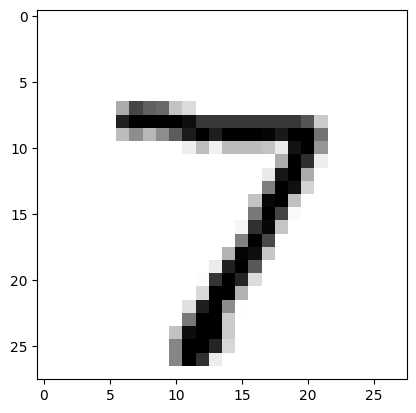

In [21]:
import matplotlib.pyplot as plt
digit = test_images[0].reshape(28,28)
plt.imshow(digit, cmap=plt.cm.binary)
plt.show()

In [22]:
# evaluatie van het model
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc}")

313/313 [==============================] - 0s 1ms/step - loss: 0.0985 - accuracy: 0.9846
Test accuracy: 0.9846000075340271


In [129]:
# Lichte overfit: test accuracy is lager dan de accuracy op de training set!

In [23]:
# De call naar fit() retourneert een History-object. Dit object bevat een history-veld, dat een dict is die 
# sleutels zoals "loss" of specifieke metrieknamen toewijst aan de lijst van hun waarden per epoch.

history.history

{'loss': [0.26113367080688477,
  0.103162981569767,
  0.06884543597698212,
  0.05112575739622116,
  0.03829397261142731,
  0.02964784763753414,
  0.022186165675520897,
  0.018853455781936646,
  0.014191909693181515,
  0.012110301293432713,
  0.009121385402977467,
  0.0074142771773040295,
  0.007276856806129217,
  0.004936400335282087,
  0.004513849969953299,
  0.003081705654039979,
  0.003332628635689616,
  0.0024690511636435986,
  0.002195429289713502,
  0.00125031522475183,
  0.0005790007999166846,
  0.0003556872543413192,
  0.0002163357858080417,
  2.1944786567473784e-05,
  1.483018058934249e-05,
  1.2738708392134868e-05,
  1.1438221008575056e-05,
  1.0438787285238504e-05,
  9.650535503169522e-06,
  8.927676390158013e-06,
  8.472954505123198e-06,
  7.980295777088031e-06,
  7.586969331896398e-06,
  7.229377843032125e-06,
  6.924000444996636e-06,
  6.626446520385798e-06,
  6.38402889308054e-06,
  6.136529009381775e-06,
  5.927758593315957e-06,
  5.738883828598773e-06,
  5.559326382353